# Target store expansion and geographic analysis
## Business question
How is the store footprint distributed across markets, and what opening patterns appear in the dataset?

This notebook reproduces the original portfolio's saved chart outputs: 1,829 mapped store rows, 17 markets and 50 states reported in the original run. The raw 47-column `target.csv` was not included in the original repository. Market counts and opening counts below were recovered from those saved chart traces; the market file contains the top 15 markets only. These are historical descriptive outputs, not current store counts or revenue data.


In [1]:
from pathlib import Path
import io,json,gzip
from urllib.request import urlopen
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
BASE="https://anjanasriya20-alt.github.io/Anjana-Sriya-/"
def data_bytes(name):
    local=Path("data")/name
    if local.exists(): return local.read_bytes()
    with urlopen(BASE+"data/"+name,timeout=60) as r:return r.read()
def csv(name):return pd.read_csv(io.BytesIO(data_bytes(name)))
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False})


In [2]:
markets=csv("target-top-markets.csv")
openings=csv("target-openings.csv")
locations=csv("target-locations.csv")
assert len(locations)==1829
assert markets.stores.ge(0).all() and openings.stores_opened.ge(0).all()
print("Mapped store records:",len(locations))
print(markets.to_string(index=False))


Mapped store records: 1829
market  stores
   RG2     394
   RG4     239
   RG3     216
   RG1     210
   ENE     149
   EMW     140
   ESE     116
   SFL      88
   ESF      49
   RMP      32
   BTC      27
   SMN      24
   RBO      19
   RMI      17
   SMA      14


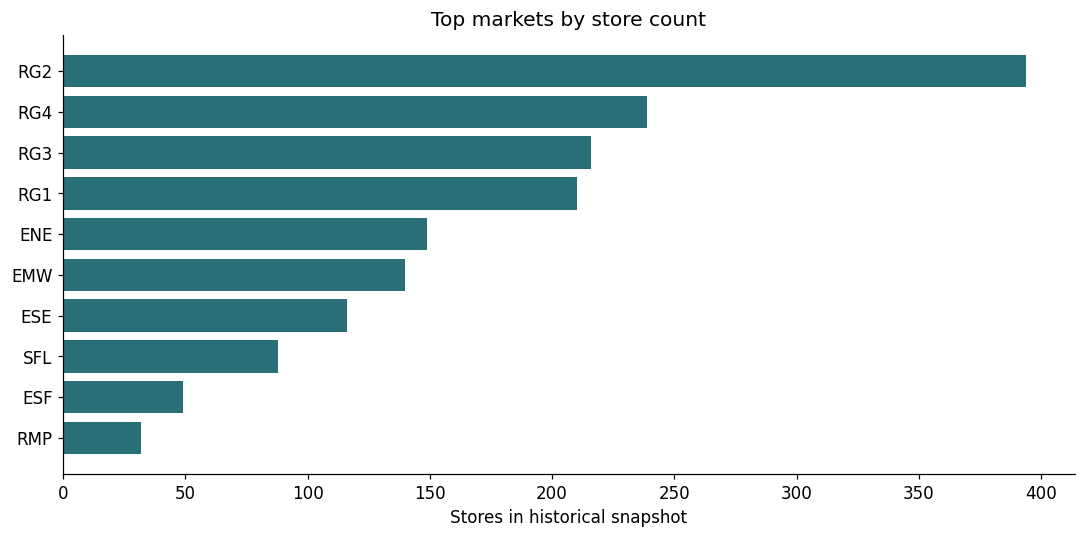

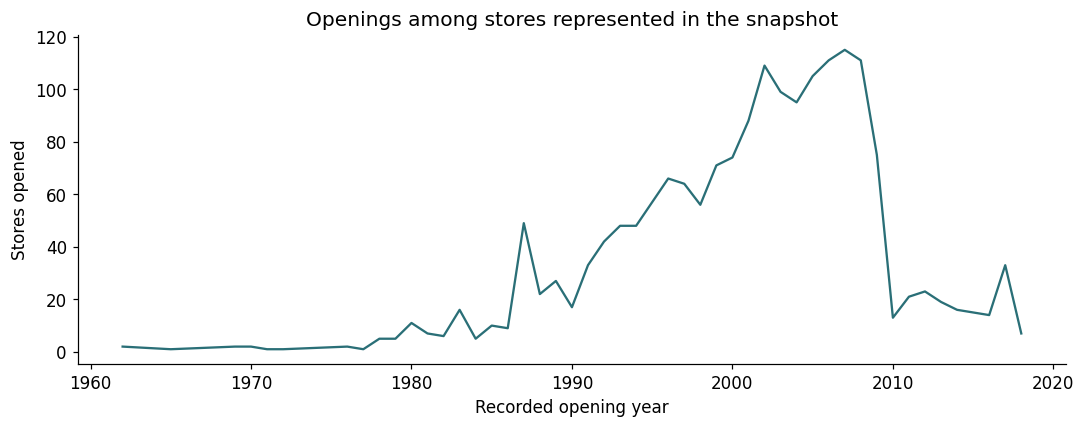

In [3]:
fig,ax=plt.subplots(figsize=(10,5))
q=markets.head(10).iloc[::-1];ax.barh(q.market,q.stores,color="#2A6F77")
ax.set_xlabel("Stores in historical snapshot");ax.set_title("Top markets by store count")
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,4));ax.plot(openings.year,openings.stores_opened,color="#2A6F77")
ax.set_xlabel("Recorded opening year");ax.set_ylabel("Stores opened")
ax.set_title("Openings among stores represented in the snapshot");plt.tight_layout();plt.show()


## Business interpretation and limits
Use market concentration and opening history to identify locations for deeper research. Expansion decisions also require demand, competition, costs, demographics and profitability. This dataset cannot establish revenue, category sales, ROI or the success of an expansion. Counts by opening year describe stores surviving in the snapshot, not all historical openings and closures. Raw-source transformations require the original `target.csv`; the saved extracts make these published charts reproducible.
